# 01 · Análisis Detallado — Mercado Informal (Revolico)

**Notebook de apoyo (Fase 5 - EDA)**

Este notebook analiza en detalle el mercado informal de venta de automóviles en La Habana, a partir de los anuncios publicados en Revolico.

| Dataset | Registros | Archivo |
|---|---|---|
| Mercado informal (Revolico) | 30 anuncios | `data/processed_final/anuncios_revolico_final.json` |

## 1. Librerías y configuración

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

FIG_DIR = Path("reports") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = BASE / "data" / "processed_final"

def cargar_json(ruta):
    with open(ruta, encoding="utf-8") as archivo:
        return json.load(archivo)

anuncios = cargar_json(DATA / "anuncios_revolico_final.json")
df = pd.DataFrame(anuncios)

print("Anuncios cargados:", len(df))
print("Columnas:", list(df.columns))

Anuncios cargados: 30
Columnas: ['id_anuncio', 'url', 'titulo_original', 'precio_anuncio', 'moneda_anuncio', 'precio_MN', 'ubicacion', 'marca', 'modelo', 'tipo_vehiculo', 'ano', 'tipo_motorizacion']


## 2. Estadísticas descriptivas generales

In [2]:
print("=== RESUMEN GENERAL ===")
print("Total de anuncios:", len(df))
print("Precio min (USD):", df["precio_anuncio"].min())
print("Precio max (USD):", df["precio_anuncio"].max())
print("Precio mediana (USD):", df["precio_anuncio"].median())
print("Precio promedio (USD):", round(df["precio_anuncio"].mean(), 2))
print("Año min:", df["ano"].min(), "| Año max:", df["ano"].max())
print("IDs únicos:", df["id_anuncio"].nunique(), "de", len(df))

print("\n=== MARCAS ===")
print(df["marca"].value_counts().to_string())

print("\n=== TIPO DE VEHÍCULO ===")
print(df["tipo_vehiculo"].value_counts().to_string())

print("\n=== MOTORIZACIÓN ===")
print(df["tipo_motorizacion"].value_counts().to_string())

print("\n=== AÑO ===")
print(df["ano"].value_counts().sort_index().to_string())

print("\n=== UBICACIÓN ===")
print(df["ubicacion"].value_counts().to_string())

=== RESUMEN GENERAL ===
Total de anuncios: 30
Precio min (USD): 10000
Precio max (USD): 100000
Precio mediana (USD): 31000.0
Precio promedio (USD): 31903.33
Año min: 2009 | Año max: 2026
IDs únicos: 30 de 30

=== MARCAS ===
marca
Hyundai     19
Kia          5
Nissan       1
Honda        1
Toyota       1
BMW          1
Dongfeng     1
Geely        1

=== TIPO DE VEHÍCULO ===
tipo_vehiculo
SUV          15
Sedán         9
Hatchback     5
Deportivo     1

=== MOTORIZACIÓN ===
tipo_motorizacion
combustible    27
electrico       3

=== AÑO ===
ano
2009    3
2010    1
2012    1
2015    1
2017    1
2018    1
2019    1
2021    6
2022    6
2023    3
2024    3
2025    1
2026    2

=== UBICACIÓN ===
ubicacion
La Habana, Playa              9
La Habana, Arroyo Naranjo     8
La Habana, La Lisa            2
La Habana, Diez de Octubre    2
La Habana, Habana Vieja       2
La Habana, Marianao           2
La Habana, Centro Habana      2
La Habana, Cerro              1
La Habana, Plaza              1
La Hab

## 3. Análisis de precios

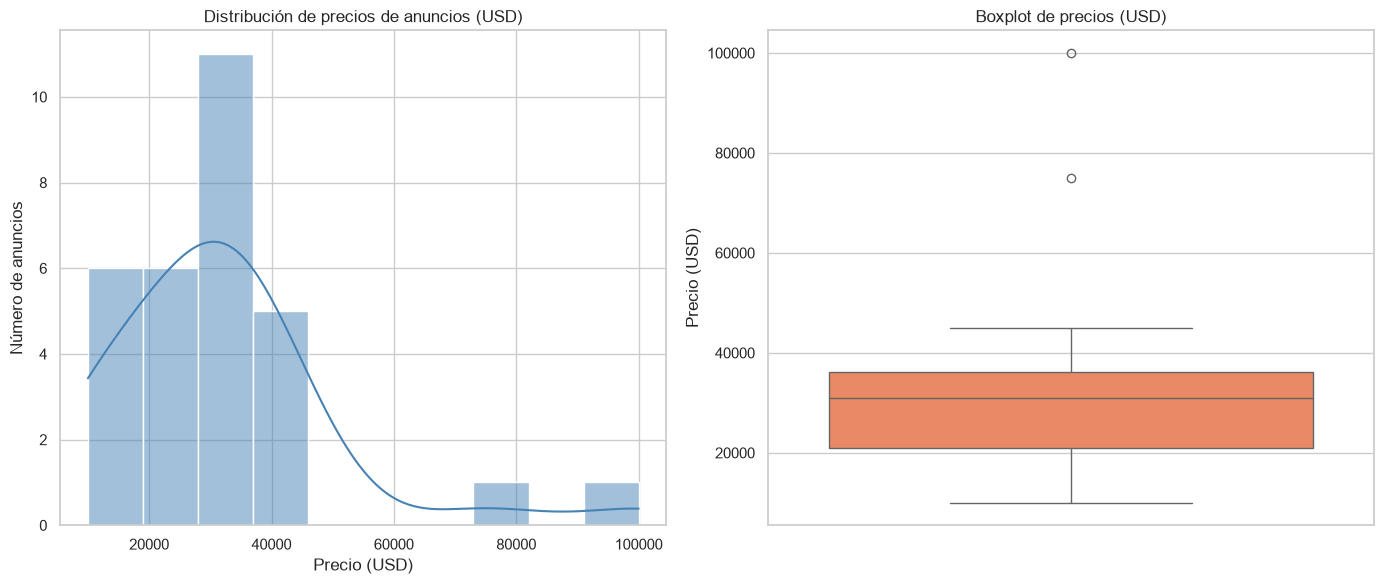

Precio promedio: 31903.33 USD
Precio mediana: 31000.0 USD
Precio mínimo: 10000 USD
Precio máximo: 100000 USD


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(data=df, x="precio_anuncio", kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribución de precios de anuncios (USD)")
axes[0].set_xlabel("Precio (USD)")
axes[0].set_ylabel("Número de anuncios")

sns.boxplot(data=df, y="precio_anuncio", ax=axes[1], color="coral")
axes[1].set_title("Boxplot de precios (USD)")
axes[1].set_ylabel("Precio (USD)")

plt.tight_layout()
plt.savefig(FIG_DIR / "f01_distribucion_precios.png", dpi=150, bbox_inches="tight")
plt.show()

print("Precio promedio:", round(df["precio_anuncio"].mean(), 2), "USD")
print("Precio mediana:", df["precio_anuncio"].median(), "USD")
print("Precio mínimo:", df["precio_anuncio"].min(), "USD")
print("Precio máximo:", df["precio_anuncio"].max(), "USD")

          count      mean   median    min     max
marca                                            
Hyundai      19  31921.05  29500.0  10000  100000
Kia           5  30100.00  34000.0  12000   36500
BMW           1  75000.00  75000.0  75000   75000
Dongfeng      1  33000.00  33000.0  33000   33000
Honda         1  26000.00  26000.0  26000   26000
Geely         1  11600.00  11600.0  11600   11600
Nissan        1  30000.00  30000.0  30000   30000
Toyota        1  24500.00  24500.0  24500   24500


C:\Users\jorge\AppData\Local\Temp\ipykernel_7148\407414576.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.index, y=top10.values, ax=ax, palette="viridis")


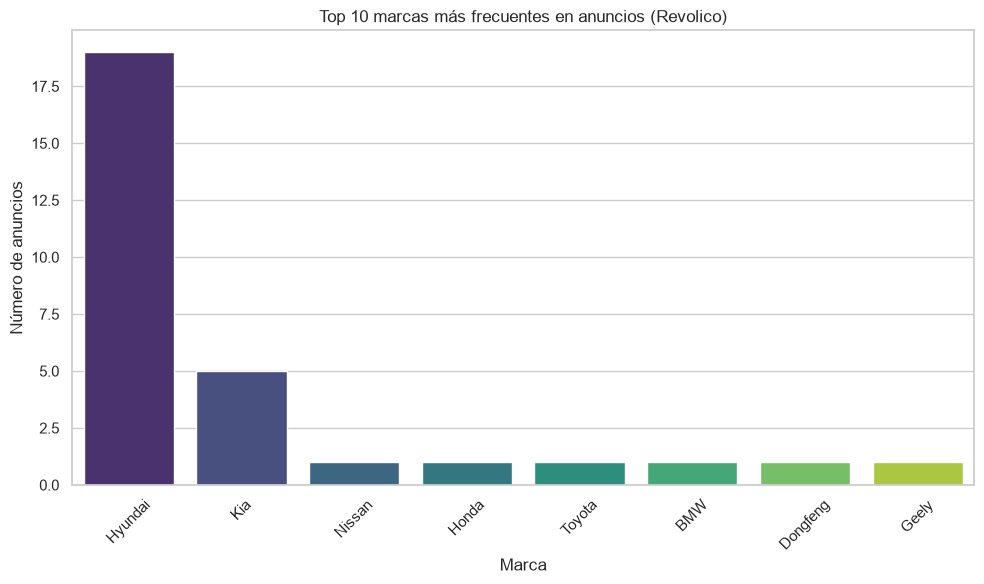

In [4]:
precio_marca = (
    df.groupby("marca")["precio_anuncio"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("count", ascending=False)
)
print(precio_marca.to_string())

fig, ax = plt.subplots(figsize=(10, 6))
top10 = df["marca"].value_counts().head(10)
sns.barplot(x=top10.index, y=top10.values, ax=ax, palette="viridis")
ax.set_title("Top 10 marcas más frecuentes en anuncios (Revolico)")
ax.set_xlabel("Marca")
ax.set_ylabel("Número de anuncios")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "f06_marcas_frecuentes.png", dpi=150, bbox_inches="tight")
plt.show()

Precio por tipo de vehículo:
               count      mean   median
tipo_vehiculo                          
Deportivo          1  75000.00  75000.0
Hatchback          5  11200.00  12000.0
SUV               15  35433.33  34000.0
Sedán              9  32733.33  26000.0


C:\Users\jorge\AppData\Local\Temp\ipykernel_7148\1952086295.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=precio_tipo.index, y=precio_tipo["mean"], ax=ax, palette="mako")


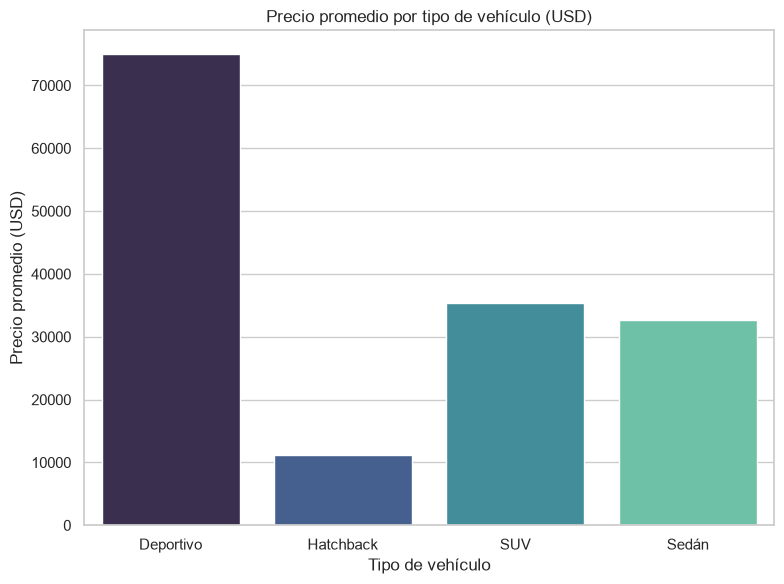

In [5]:
precio_tipo = df.groupby("tipo_vehiculo")["precio_anuncio"].agg(["count", "mean", "median"]).round(2)
print("Precio por tipo de vehículo:")
print(precio_tipo.to_string())

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=precio_tipo.index, y=precio_tipo["mean"], ax=ax, palette="mako")
ax.set_title("Precio promedio por tipo de vehículo (USD)")
ax.set_xlabel("Tipo de vehículo")
ax.set_ylabel("Precio promedio (USD)")
plt.tight_layout()
plt.savefig(FIG_DIR / "f03_tipos_vehiculo.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
precio_ano = df.groupby("ano")["precio_anuncio"].agg(["count", "mean", "median"]).round(2)
print("Precio por año:")
print(precio_ano.to_string())

Precio por año:
      count      mean   median
ano                           
2009      3  10666.67  10000.0
2010      1  12000.00  12000.0
2012      1  12000.00  12000.0
2015      1  11600.00  11600.0
2017      1  20500.00  20500.0
2018      1  22000.00  22000.0
2019      1  20000.00  20000.0
2021      6  48000.00  44250.0
2022      6  32083.33  34000.0
2023      3  33000.00  28000.0
2024      3  34333.33  35000.0
2025      1  36500.00  36500.0
2026      2  54000.00  54000.0


## 4. Comparación eléctrico vs combustión

Precio por motorización:
                   count      mean   median
tipo_motorizacion                          
combustible           27  31522.22  29500.0
electrico              3  35333.33  35000.0


C:\Users\jorge\AppData\Local\Temp\ipykernel_7148\904606474.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=motor_counts.index, y=motor_counts.values, ax=axes[0], palette="Set2")
C:\Users\jorge\AppData\Local\Temp\ipykernel_7148\904606474.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="tipo_motorizacion", y="precio_anuncio", ax=axes[1], palette="Set2")


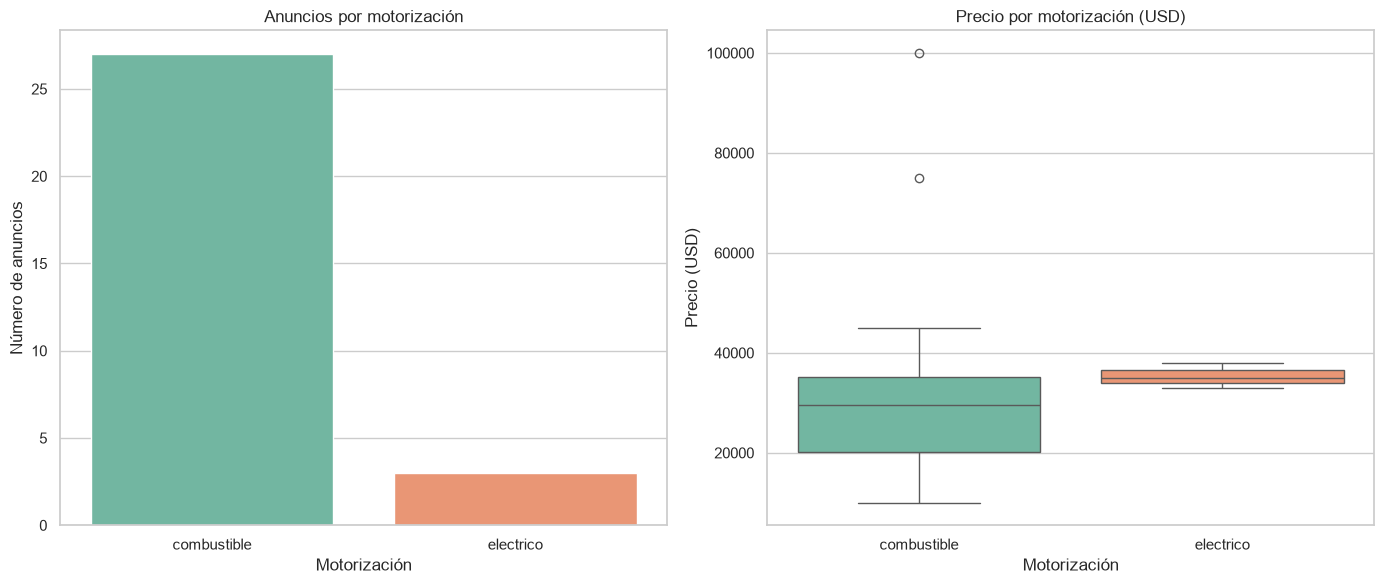


Vehículos eléctricos: 3
   marca  modelo  ano  precio_anuncio               ubicacion
 Hyundai   Ioniq 2024           35000 La Habana, Habana Vieja
 Hyundai Ioniq 5 2024           38000        La Habana, Playa
Dongfeng     BOX 2026           33000        La Habana, Playa

Vehículos de combustión: 27
Precio promedio eléctricos: 35333.33 USD
Precio promedio combustión: 31522.22 USD


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

motor_counts = df["tipo_motorizacion"].value_counts()
sns.barplot(x=motor_counts.index, y=motor_counts.values, ax=axes[0], palette="Set2")
axes[0].set_title("Anuncios por motorización")
axes[0].set_xlabel("Motorización")
axes[0].set_ylabel("Número de anuncios")

precio_motor = df.groupby("tipo_motorizacion")["precio_anuncio"].agg(["count", "mean", "median"]).round(2)
print("Precio por motorización:")
print(precio_motor.to_string())

sns.boxplot(data=df, x="tipo_motorizacion", y="precio_anuncio", ax=axes[1], palette="Set2")
axes[1].set_title("Precio por motorización (USD)")
axes[1].set_xlabel("Motorización")
axes[1].set_ylabel("Precio (USD)")

plt.tight_layout()
plt.savefig(FIG_DIR / "f04_electrico_vs_combustion.png", dpi=150, bbox_inches="tight")
plt.show()

ev = df[df["tipo_motorizacion"] == "electrico"]
comb = df[df["tipo_motorizacion"] == "combustible"]
print("\nVehículos eléctricos:", len(ev))
print(ev[['marca', 'modelo', 'ano', 'precio_anuncio', 'ubicacion']].to_string(index=False))
print("\nVehículos de combustión:", len(comb))
print("Precio promedio eléctricos:", round(ev["precio_anuncio"].mean(), 2), "USD")
print("Precio promedio combustión:", round(comb["precio_anuncio"].mean(), 2), "USD")

## 5. Análisis de marcas

In [8]:
top_marcas = df["marca"].value_counts().head(10)
print("Top 10 marcas:")
print(top_marcas.to_string())

print("\nDistribución de tipos de vehículo por marca:")
tipo_por_marca = pd.crosstab(df["marca"], df["tipo_vehiculo"])
print(tipo_por_marca.to_string())

Top 10 marcas:
marca
Hyundai     19
Kia          5
Nissan       1
Honda        1
Toyota       1
BMW          1
Dongfeng     1
Geely        1

Distribución de tipos de vehículo por marca:
tipo_vehiculo  Deportivo  Hatchback  SUV  Sedán
marca                                          
BMW                    1          0    0      0
Dongfeng               0          0    1      0
Geely                  0          0    0      1
Honda                  0          0    0      1
Hyundai                0          4   10      5
Kia                    0          1    4      0
Nissan                 0          0    0      1
Toyota                 0          0    0      1


## 6. Análisis temporal (año del vehículo)

C:\Users\jorge\AppData\Local\Temp\ipykernel_7148\1726474234.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ano_counts.index.astype(str), y=ano_counts.values, ax=ax, palette="rocket")


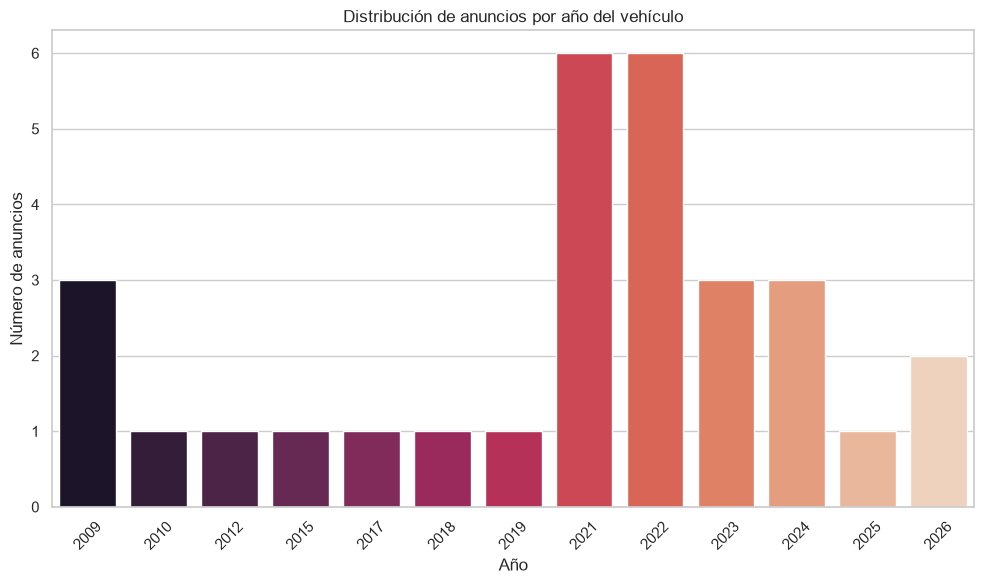

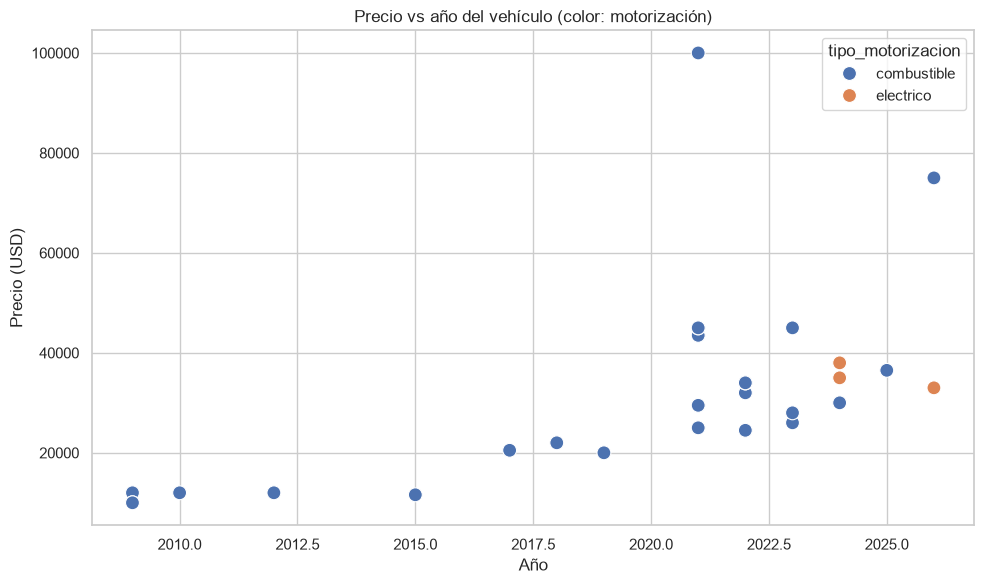

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
ano_counts = df["ano"].value_counts().sort_index()
sns.barplot(x=ano_counts.index.astype(str), y=ano_counts.values, ax=ax, palette="rocket")
ax.set_title("Distribución de anuncios por año del vehículo")
ax.set_xlabel("Año")
ax.set_ylabel("Número de anuncios")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "f02_distribucion_anos.png", dpi=150, bbox_inches="tight")
plt.show()

fig2, ax2 = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="ano", y="precio_anuncio", hue="tipo_motorizacion", 
                s=100, ax=ax2, palette="deep")
ax2.set_title("Precio vs año del vehículo (color: motorización)")
ax2.set_xlabel("Año")
ax2.set_ylabel("Precio (USD)")
plt.tight_layout()
plt.savefig(FIG_DIR / "f05_precio_vs_ano.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Conclusiones del mercado informal

- **Hyundai domina** el mercado informal con 19 de 30 anuncios (63%).
- **SUV es el tipo más frecuente** (15 anuncios, 50%), seguido de Sedán (9).
- Solo **3 de 30 anuncios son vehículos eléctricos** (10%): 2 Hyundai Ioniq 5 y 1 Dongfeng BOX.
- Los vehículos eléctricos tienen precios más altos (promedio ~35,667 USD) que los de combustión.
- Hay presencia de vehículos tanto antiguos (2009-2015) como modernos (2021-2026), lo que indica que los clásicos **no han desaparecido**.
- Marcas chinas (Dongfeng, Geely) empiezan a aparecer en el mercado informal.